In [ ]:
!pip install ipython-autotime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 19.6 MB/s eta 0:00:00


In [ ]:
%load_ext autotime

time: 1.66 ms (started: 2024-12-01 19:13:03 +00:00)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

time: 544 µs (started: 2024-12-01 19:13:03 +00:00)


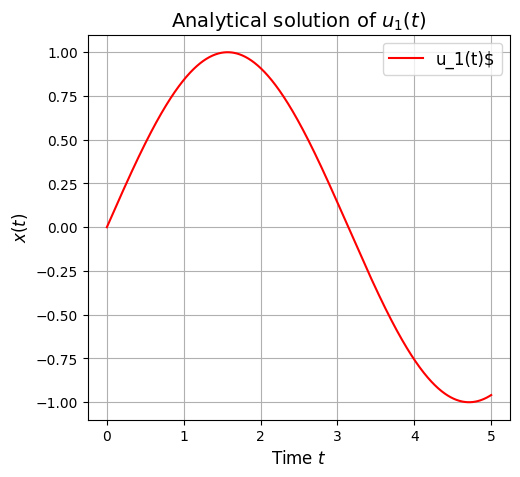

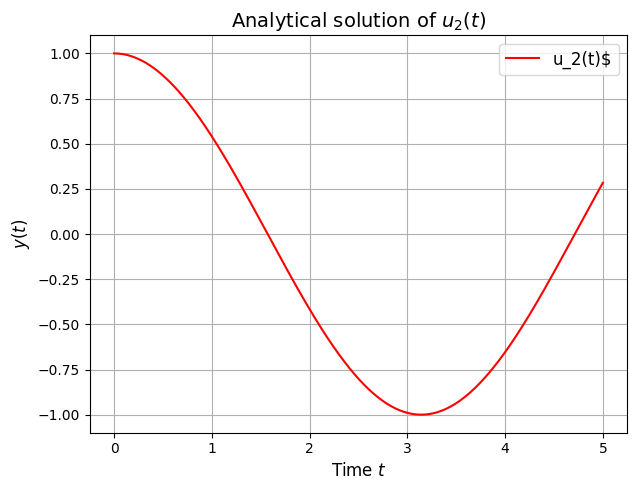

time: 2.12 s (started: 2024-12-01 19:13:03 +00:00)


In [ ]:
#Training dataset
t = np.linspace(0,5,1022)

x_analytical = np.sin(t)
y_analytical = np.cos(t)
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(t,x_analytical,label=r'u_1(t)$',color = 'red')
plt.title(r'Analytical solution of $u_1(t)$',fontsize =14)
plt.xlabel(r'Time $t$',fontsize = 12)
plt.ylabel(r'$x(t)$',fontsize = 12)
plt.grid(True)
plt.legend(fontsize = 12, loc="upper right")


plt.figure(figsize=(12,5))
plt.subplot(1,2,2)
plt.plot(t,y_analytical,label=r'u_2(t)$',color = 'red')
plt.title(r'Analytical solution of $u_2(t)$',fontsize =14)
plt.xlabel(r'Time $t$',fontsize = 12)
plt.ylabel(r'$y(t)$',fontsize = 12)
plt.grid(True)
plt.legend(fontsize = 12, loc="upper right")
plt.tight_layout()

In [ ]:
import tensorflow as tf

class PINN(tf.keras.Model):
    def __init__(self):
        super(PINN,self).__init__()
        self.dense1= tf.keras.layers.Dense(64, activation = 'tanh')
        self.dense2= tf.keras.layers.Dense(64, activation = 'tanh')
        self.dense3= tf.keras.layers.Dense(2, activation = None)

    def call(self,t):
        t=self.dense1(t)
        t=self.dense2(t)
        return self.dense3(t)

time: 10.3 s (started: 2024-12-01 19:13:05 +00:00)


In [ ]:
def loss_fn(model,t):
    with tf.GradientTape() as tape1, tf.GradientTape() as tape2:
        tape1.watch(t)
        tape2.watch(t)
        output=model(t)
        x=output[:,0:1]
        y=output[:,1:2]
        dxdt = tape1.gradient(x,t)
        dydt = tape2.gradient(y,t)
        #Formula
        res_x = dxdt-y
        res_y = dydt+x
        #Initial Value
        init_loss_x = tf.square(x[0]-0)
        init_loss_y = tf.square(y[0]-1)
        loss = tf.reduce_mean(tf.square(res_x)) + tf.reduce_mean(tf.square(res_y)) + init_loss_x + init_loss_y
    return loss

time: 6.29 ms (started: 2024-12-01 19:13:15 +00:00)


In [ ]:
def train(model,t,epos,optimizer):
    for epo in range (epos):
        with tf.GradientTape() as tape:
            loss = loss_fn(model, t)
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        if epo%500 ==0:
            print(f'Epoch{epo}: Loss = {loss.numpy()}')

time: 908 µs (started: 2024-12-01 19:13:15 +00:00)


In [ ]:
model = PINN()
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

time: 63.3 ms (started: 2024-12-01 19:13:16 +00:00)


In [ ]:
t = tf.convert_to_tensor(np.linspace(0,5,1022)[:,None],dtype=tf.float32)

time: 1.3 ms (started: 2024-12-01 19:13:16 +00:00)


In [ ]:
train(model,t,epos = 4000,optimizer = optimizer)

Epoch0: Loss = [1.7428114]
Epoch500: Loss = [0.02947976]
Epoch1000: Loss = [0.01965887]
Epoch1500: Loss = [0.00618312]
Epoch2000: Loss = [0.00164165]
Epoch2500: Loss = [0.00066122]
Epoch3000: Loss = [0.00034297]
Epoch3500: Loss = [0.00019329]
time: 3min 59s (started: 2024-12-01 19:13:16 +00:00)


In [ ]:
t_test = np.linspace(0,5,300)[:,None]
x_pred,y_pred = model(t_test).numpy().T

time: 10.2 ms (started: 2024-12-01 19:17:15 +00:00)


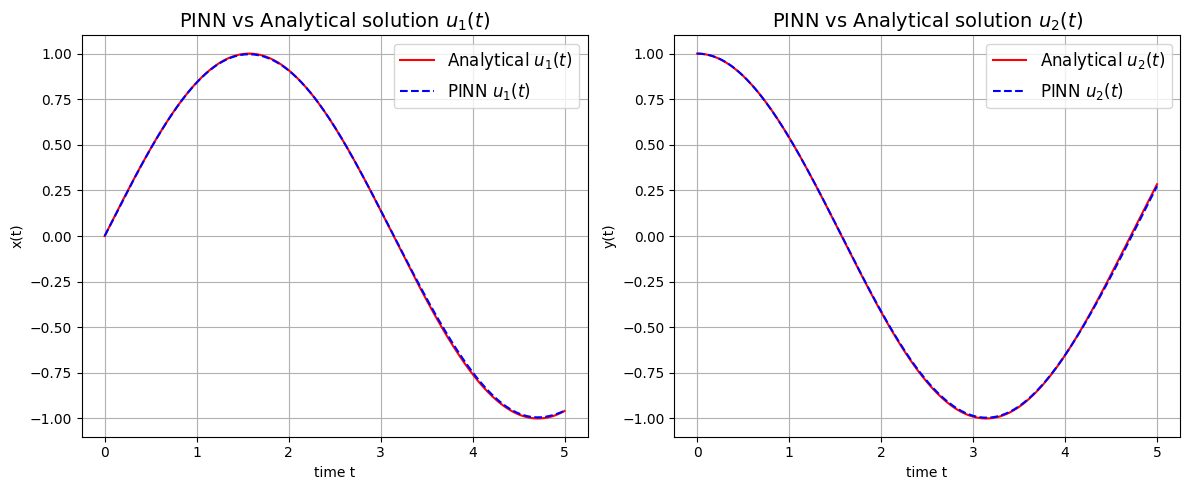

time: 627 ms (started: 2024-12-01 19:17:15 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(t_test,np.reshape(np.sin(t_test),(-1)),label ="Analytical $u_1(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $u_1(t)$",color='blue')
plt.title(r'PINN vs Analytical solution $u_1(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'x(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(t_test,np.reshape(np.cos(t_test),(-1)),label ="Analytical $u_2(t)$",color='red')
plt.plot(t_test,y_pred,'--',label ="PINN $u_2(t)$",color='blue')
plt.title(r'PINN vs Analytical solution $u_2(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'y(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()

In [ ]:
#Mean-squared error
np.sum(np.abs(np.reshape(np.sin(t_test),(-1))-x_pred)**2+np.abs(np.reshape(np.cos(t_test),(-1))-y_pred)**2)/300

5.331026953056133e-05

time: 13 ms (started: 2024-12-01 19:17:15 +00:00)


In [ ]:
#Neurodiffeq

time: 338 µs (started: 2024-12-01 19:17:15 +00:00)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

time: 595 µs (started: 2024-12-01 19:17:15 +00:00)


In [ ]:
!pip install neurodiffeq
from neurodiffeq import diff

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 76.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 9.7 MB/s eta 0:00:00
  Created wheel for neurodiffeq: filename=neurodiffeq-0.6.3-py3-none-any.whl size=132419 sha256=3a615dc849647931f920a9b2b8af4a258c43f463415344677218e7217dc31a2b
  Stored in directory: /root/.cache/pip/wheels/f6/e7/71/84c06f693bbf2ffd52a7c5ecd416c2a2ac053569b283171ddf
Successfully built neurodiffeq
time: 13.6 s (started: 2024-12-01 19:17:15 +00:00)


In [ ]:
from neurodiffeq import diff      # the differentiation operation
from neurodiffeq.ode import solve # the ANN-based solver
from neurodiffeq.conditions import IVP   # the initial condition
from neurodiffeq.monitors import Monitor1D

time: 540 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
from neurodiffeq.ode import solve_system

time: 546 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
import torch

time: 502 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
from neurodiffeq.networks import FCNN # fully-connect neural network
import torch.nn as nn                 # PyTorch neural network module

time: 586 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
from neurodiffeq.generators import Generator1D

time: 495 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
from neurodiffeq.solvers import Solver1D

time: 525 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

time: 452 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
from neurodiffeq.neurodiffeq import safe_diff as diff
from neurodiffeq.ode import solve, solve_system

time: 400 µs (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
%matplotlib inline

time: 1.18 ms (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
net_ho = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(64, 64),
    actv=nn.Tanh

)
net_ho_1 = FCNN(
    n_input_units=1,
    n_output_units=1,
)

time: 44.7 ms (started: 2024-12-01 19:17:29 +00:00)


/usr/local/lib/python3.10/dist-packages/neurodiffeq/ode.py:260: FutureWarning: The `solve_system` function is deprecated, use a `neurodiffeq.solvers.Solver1D` instance instead
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/neurodiffeq/solvers.py:469: UserWarning: Passing `monitor` is deprecated, use a MonitorCallback and pass a list of callbacks instead
  warnings.warn("Passing `monitor` is deprecated, "


Training Progress:   0%|          | 0/4000 [00:00<?, ?it/s]

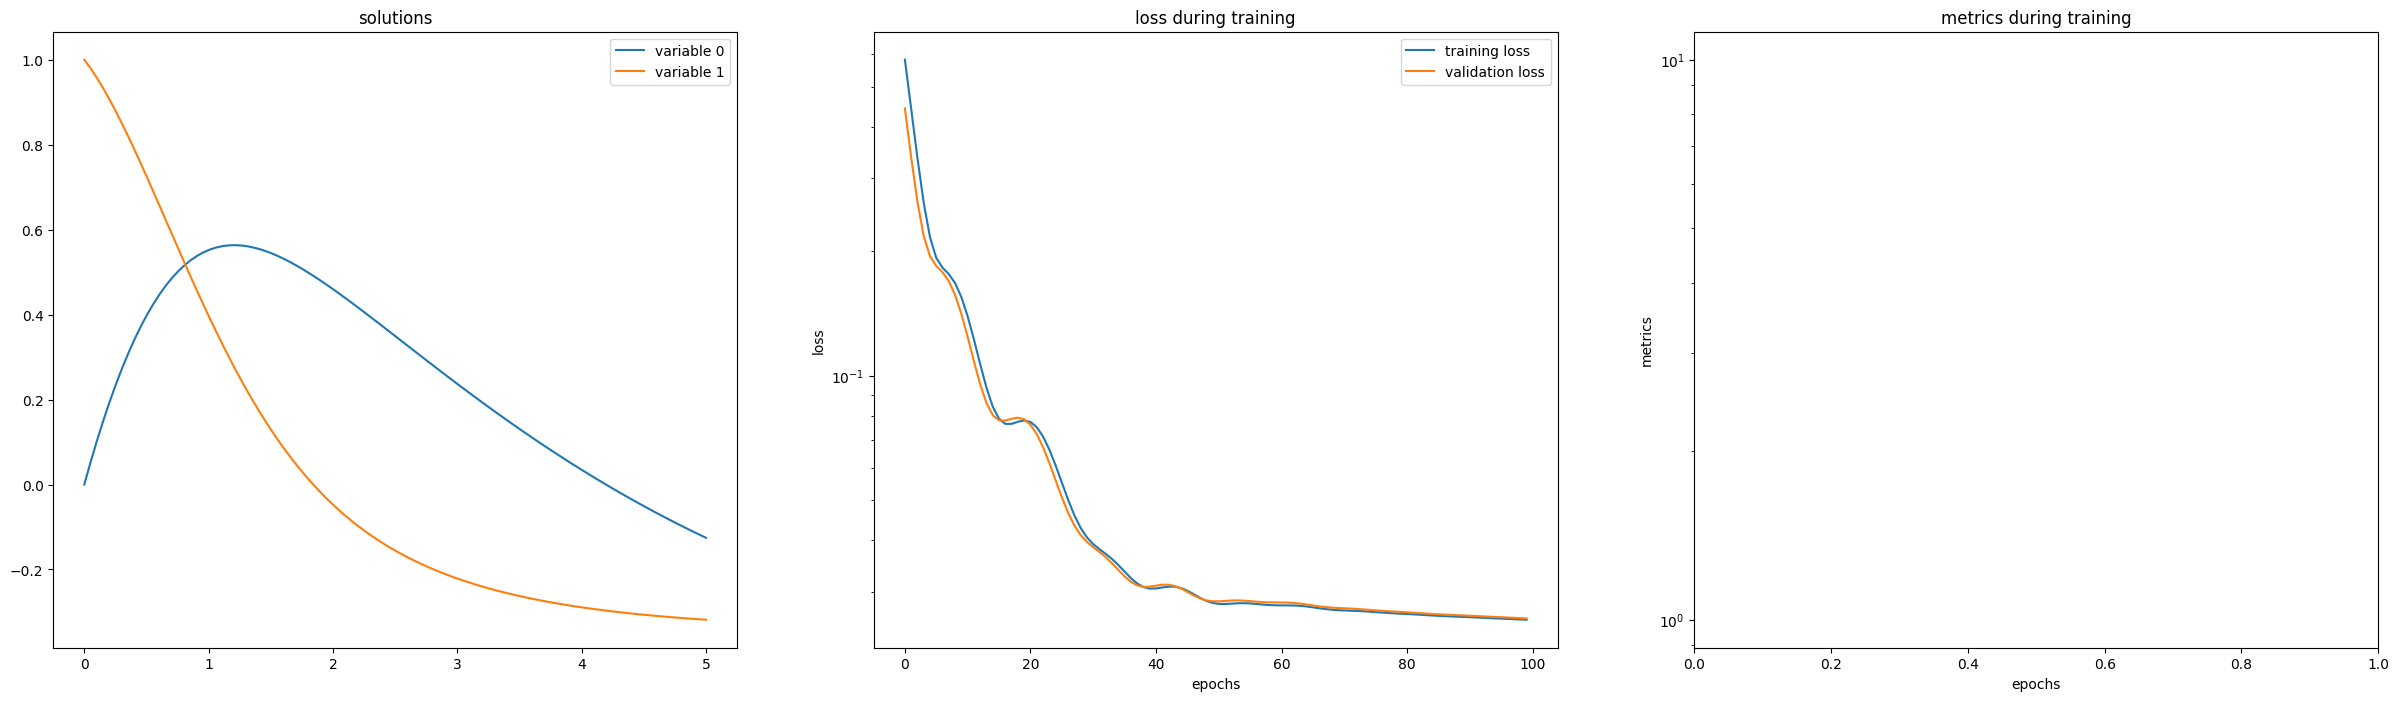

time: 2min 26s (started: 2024-12-01 19:17:29 +00:00)


In [ ]:
# specify the ODE system
la=0.02
mu=0.0202

queueing_theory_equation = lambda y0, y1, t : [diff(y0, t)-y1,
                           diff(y1, t)+y0

                                                               ]
# specify the initial conditions
init_vals_pc = [
    IVP(t_0=0.0, u_0=0.0),
    IVP(t_0=0.0, u_0=1.0),
]
train_gen=Generator1D(size=1022,  t_min=0.0, t_max=5, method='equally-spaced')
valid_gen = Generator1D(size=100, t_min=0.0, t_max=5, method='equally-spaced')
# solve the ODE system
solution_pc, _, internal = solve_system(
    ode_system=queueing_theory_equation, conditions=init_vals_pc, t_min=0, t_max=5,
    train_generator=train_gen,
    valid_generator=valid_gen,
    max_epochs=4000,
    monitor=Monitor1D(t_min=0, t_max=5, check_every=100), return_internal=True,
    nets=[net_ho,net_ho_1],
)

In [ ]:
internal

{'nets': [FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
      (4): Linear(in_features=64, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=32, bias=True)
      (1): Tanh()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): Tanh()
      (4): Linear(in_features=32, out_features=1, bias=True)
    )
  )],
 'conditions': [<neurodiffeq.conditions.IVP at 0x7b267e656d10>,
 'train_generator': SamplerGenerator(size=1022, generator=Generator1D(size=1022, t_min=0.0, t_max=5, method='equally-spaced', noise_std=0.001223091976516634)),
 'valid_generator': SamplerGenerator(size=100, generator=Generator1D(size=100, t_min=0.0, t_max=5, method='equally-spaced', noise_std=0.0125)),
 'optimizer': Adam (
 Parameter Group 0
     amsgrad: False
     betas: (0.9, 0.999)
     capturable:

time: 4.22 ms (started: 2024-12-01 19:19:56 +00:00)


In [ ]:
from time import time
time0=time()
ts = np.linspace(0, 5, 300)
u_net = solution_pc(ts, to_numpy=True)
time1=time()

time: 5.2 ms (started: 2024-12-01 19:19:56 +00:00)


In [ ]:
time=time1-time0
time

0.004407405853271484

time: 4.73 ms (started: 2024-12-01 19:19:56 +00:00)


In [ ]:
#L2 loss
np.sum(np.abs(np.reshape(np.sin(t_test),(-1))-u_net[0])**2+np.abs(np.reshape(np.cos(t_test),(-1))-u_net[1])**2)/300

1.7736359650150257e-07

time: 4 ms (started: 2024-12-01 19:19:56 +00:00)


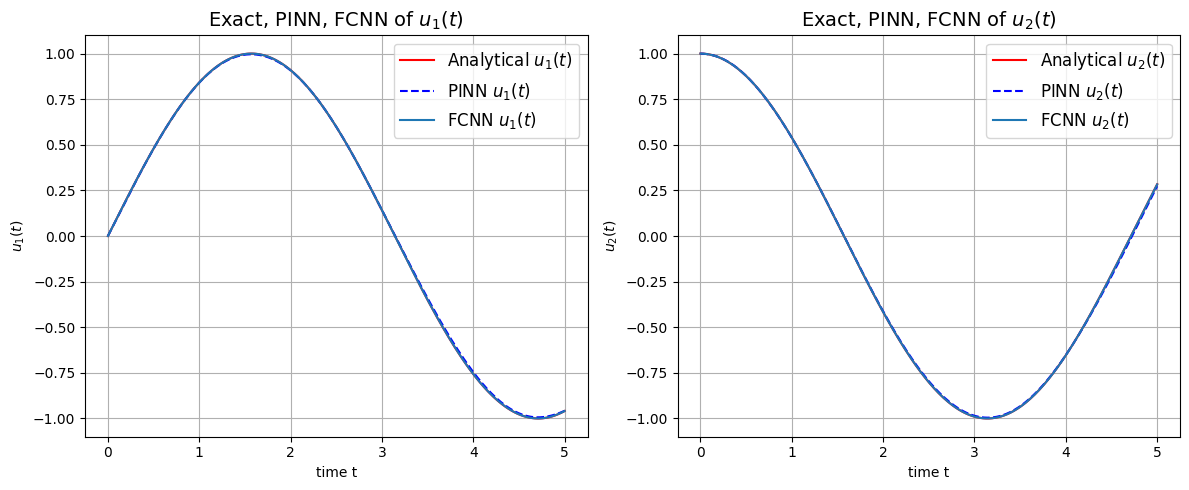

time: 779 ms (started: 2024-12-01 19:19:56 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(t_test,np.reshape(np.sin(t_test),(-1)),label ="Analytical $u_1(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $u_1(t)$",color='blue')
plt.plot(ts, u_net[0],label ="FCNN $u_1(t)$")
plt.title(r'Exact, PINN, FCNN of $u_1(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$u_1(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(t_test,np.reshape(np.cos(t_test),(-1)),label ="Analytical $u_2(t)$",color='red')
plt.plot(t_test,y_pred,'--',label ="PINN $u_2(t)$",color='blue')
plt.plot(ts, u_net[1],label ="FCNN $u_2(t)$")
plt.title(r'Exact, PINN, FCNN of $u_2(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$u_2(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.cm import rainbow
import numpy as np
from scipy.integrate import solve_ivp
from scipy.io import loadmat
!pip install pysindy
from pysindy.utils import linear_damped_SHO
from pysindy.utils import cubic_damped_SHO
from pysindy.utils import linear_3D
from pysindy.utils import hopf
from pysindy.utils import lorenz

import pysindy as ps

# ignore user warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

np.random.seed(1000)  # Seed for reproducibility

# Integrator keywords for solve_ivp
integrator_keywords = {}
integrator_keywords['rtol'] = 1e-12
integrator_keywords['method'] = 'LSODA'
integrator_keywords['atol'] = 1e-12

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.0/121.0 kB 4.9 MB/s eta 0:00:00
time: 9.28 s (started: 2024-12-01 19:19:57 +00:00)


In [ ]:
import numpy as np
import pysindy as ps

t = np.linspace(0, 5, 500)
x = np.sin(t)
y = np.cos(t)
X = np.stack((x, y), axis=-1)  # First column is x, second is y

time: 1.68 ms (started: 2024-12-01 19:20:06 +00:00)


In [ ]:
model = ps.SINDy(feature_names=["x", "y"])
model.fit(X, t=t)

SINDy(differentiation_method=FiniteDifference(),
      feature_library=PolynomialLibrary(), feature_names=['x', 'y'],
      optimizer=STLSQ())

time: 88.3 ms (started: 2024-12-01 19:20:06 +00:00)


In [ ]:
model.print()

(x)' = 1.000 y
(y)' = -1.000 x
time: 5.17 ms (started: 2024-12-01 19:20:06 +00:00)


In [ ]:
x0, y0, t_test, x_test, y_test = gen_data2()
sim = model.simulate([x0, y0], t=t_test)

NameError: name 'gen_data2' is not defined

time: 29.8 ms (started: 2024-12-01 19:25:00 +00:00)


In [ ]:
!pip install deepxde
import deepxde as dde
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.4/184.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 9.3 MB/s eta 0:00:00


Using backend: tensorflow.compat.v1
Other supported backends: tensorflow, pytorch, jax, paddle.
paddle supports more examples now and is recommended.
Instructions for updating:
non-resource variables are not supported in the long term


No backend selected.
Finding available backend...
Found tensorflow.compat.v1
Setting the default backend to "tensorflow.compat.v1". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)
time: 4.18 s (started: 2024-12-01 19:25:23 +00:00)


In [ ]:
geom = dde.geometry.TimeDomain(0, 5)

time: 786 µs (started: 2024-12-01 19:25:30 +00:00)


In [ ]:
def ode_system(x, y):
    y1, y2 = y[:, 0:1], y[:, 1:]
    dy1_x = dde.grad.jacobian(y, x, i=0)
    dy2_x = dde.grad.jacobian(y, x, i=1)
    return [dy1_x - y2, dy2_x + y1]

time: 4.26 ms (started: 2024-12-01 19:25:31 +00:00)


In [ ]:
def boundary(x, on_initial):
    return dde.utils.isclose(x[0], 0)

time: 635 µs (started: 2024-12-01 19:25:33 +00:00)


In [ ]:
def boundary(_, on_initial):
    return on_initial

time: 528 µs (started: 2024-12-01 19:25:35 +00:00)


In [ ]:
ic1 = dde.icbc.IC(geom, lambda x: 0, boundary, component=0)
ic2 = dde.icbc.IC(geom, lambda x: 1, boundary, component=1)

time: 2.68 ms (started: 2024-12-01 19:25:37 +00:00)


In [ ]:
def func(x):
    return np.hstack((np.sin(x), np.cos(x)))

time: 881 µs (started: 2024-12-01 19:25:38 +00:00)


In [ ]:
data = dde.data.PDE(geom, ode_system, [ic1, ic2], 1022, 2, solution=func, num_test=300)

time: 95.7 ms (started: 2024-12-01 19:25:40 +00:00)


In [ ]:
layer_size = [1] + [64] * 2 + [2]
activation = "tanh"
initializer = "Glorot uniform"
net = dde.nn.FNN(layer_size, activation, initializer)

time: 14.7 ms (started: 2024-12-01 19:25:42 +00:00)


In [ ]:
model = dde.Model(data, net)
model.compile("adam", lr=0.01, metrics=["l2 relative error"])

Compiling model...
Building feed-forward neural network...
'build' took 0.461626 s

'compile' took 2.491842 s

time: 2.52 s (started: 2024-12-01 19:25:44 +00:00)


In [ ]:
losshistory, train_state = model.train(iterations=4000)

Training model...

Step      Train loss                                  Test loss                                   Test metric   
0         [1.78e-01, 2.16e-02, 0.00e+00, 1.00e+00]    [1.78e-01, 2.16e-02, 0.00e+00, 1.00e+00]    [1.25e+00]    
1000      [2.21e-04, 9.74e-05, 1.05e-06, 5.05e-06]    [2.12e-04, 9.59e-05, 1.05e-06, 5.05e-06]    [2.18e-02]    
2000      [4.62e-05, 2.04e-05, 9.47e-06, 2.52e-06]    [4.50e-05, 2.03e-05, 9.47e-06, 2.52e-06]    [4.53e-03]    
3000      [1.15e-05, 1.40e-05, 1.80e-07, 3.98e-06]    [1.13e-05, 1.40e-05, 1.80e-07, 3.98e-06]    [2.84e-03]    
4000      [2.59e-04, 6.25e-04, 2.67e-05, 2.43e-04]    [2.57e-04, 6.27e-04, 2.67e-05, 2.43e-04]    [3.17e-02]    

Best model at step 3000:
  train loss: 2.97e-05
  test loss: 2.95e-05
  test metric: [2.84e-03]

'train' took 34.651060 s

time: 34.7 s (started: 2024-12-01 19:25:49 +00:00)


Saving loss history to /content/loss.dat ...
Saving training data to /content/train.dat ...
Saving test data to /content/test.dat ...


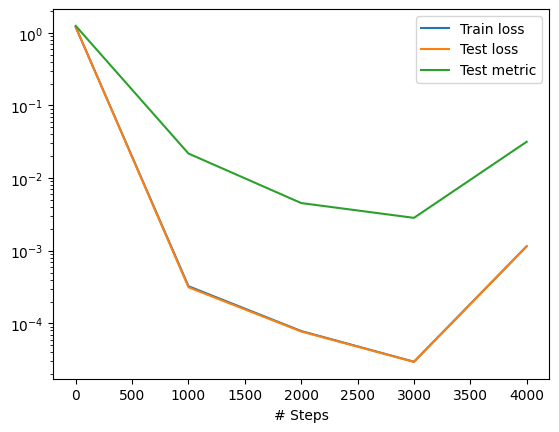

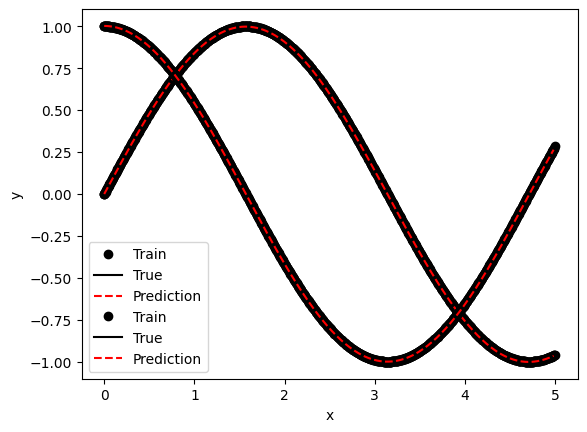

time: 826 ms (started: 2024-12-01 19:26:24 +00:00)


In [ ]:
dde.saveplot(losshistory, train_state, issave=True, isplot=True)

In [ ]:
losshistory

time: 3.04 ms (started: 2024-12-01 19:26:25 +00:00)


In [ ]:
x=model.predict(np.expand_dims(np.linspace(0,5,300),axis=-1))[:,0]
y=model.predict(np.expand_dims(np.linspace(0,5,300),axis=-1))[:,1]

time: 20.2 ms (started: 2024-12-01 19:26:25 +00:00)


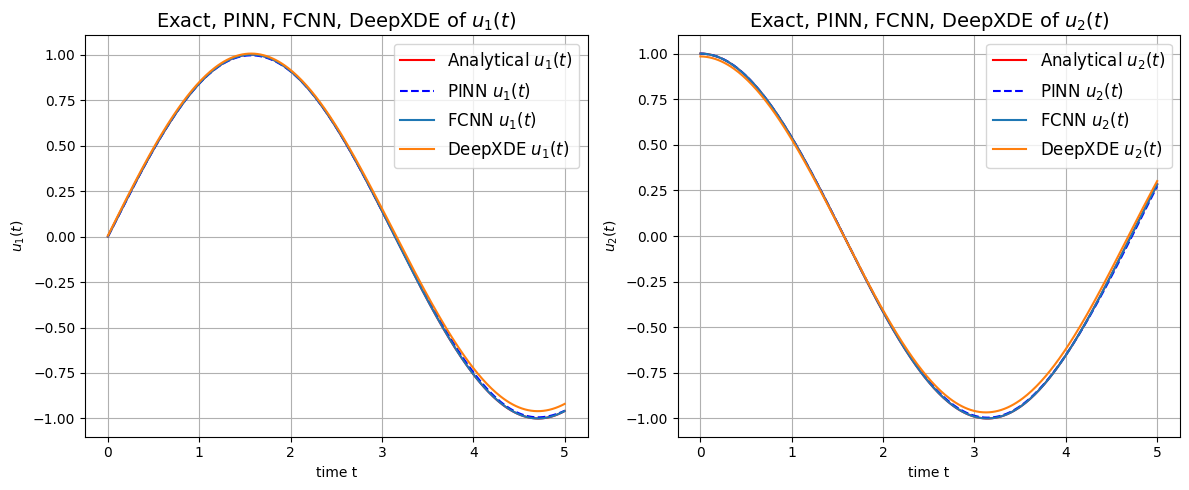

time: 699 ms (started: 2024-12-01 19:26:25 +00:00)


In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(t_test,np.reshape(np.sin(t_test),(-1)),label ="Analytical $u_1(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $u_1(t)$",color='blue')
plt.plot(ts, u_net[0],label ="FCNN $u_1(t)$")
plt.plot(ts, x,label ="DeepXDE $u_1(t)$")
plt.title(r'Exact, PINN, FCNN, DeepXDE of $u_1(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$u_1(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(t_test,np.reshape(np.cos(t_test),(-1)),label ="Analytical $u_2(t)$",color='red')
plt.plot(t_test,y_pred,'--',label ="PINN $u_2(t)$",color='blue')
plt.plot(ts, u_net[1],label ="FCNN $u_2(t)$")
plt.plot(ts, y,label ="DeepXDE $u_2(t)$")
plt.title(r'Exact, PINN, FCNN, DeepXDE of $u_2(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$u_2(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()

In [ ]:
np.sum(np.abs(np.reshape(np.sin(t_test),(-1))-x)**2+np.abs(np.reshape(np.cos(t_test),(-1))-y)**2)/300

0.001007664441523292

time: 3.92 ms (started: 2024-12-01 19:26:25 +00:00)
